# California Housing Price Regression with a Neural Network

Predict the **median house value** of a California census block group with a
feed-forward neural network built in TensorFlow/Keras, using the 1990 census
data bundled with scikit-learn (`fetch_california_housing`).

**Task:** regression - the target `MedHouseVal` is continuous and expressed in
units of **$100,000** (so `2.5` means about $250,000).

**Dataset at a glance**

| Property | Value |
| --- | --- |
| Rows | 20,640 |
| Features | 8 numeric |
| Target | `MedHouseVal` (0.15 - 5.00) |
| Missing values | none |

**Workflow**

1. Load the data and split it into train / validation / test sets.
2. Normalize the features with a Keras `Normalization` layer.
3. Build a 64-32-1 multilayer perceptron and train it with early stopping.
4. Tune L2 regularization to reduce overfitting.
5. Analyse residuals overall and by predicted price band.
6. Compare the network with a random forest on validation and test data.
7. Save the Keras model and verify that it reloads with identical predictions.

This is the neural-network counterpart to `real-estate-regression.ipynb`, which
solves the same task with classical models and a random forest.

## 1. Load and split the data

`fetch_california_housing(as_frame=True).frame` returns the full dataset as a
pandas `DataFrame`. The target is popped into `y`, leaving the eight predictors
in `df`.

The data is split 60% train / 20% validation / 20% test with a fixed
`random_state=42`. The validation split drives early stopping and model
selection; the test split is held back until the final comparison. Splitting
before normalization keeps information from the validation and test sets out of
the scaling statistics.

In [18]:
import tensorflow as tf
from sklearn.datasets import fetch_california_housing

print("TensorFlow version:", tf.__version__)
df = fetch_california_housing(as_frame=True).frame


TensorFlow version: 2.21.0


In [19]:
from sklearn.model_selection import train_test_split

y = df.pop("MedHouseVal")
X_train, X_temp, y_train, y_temp = train_test_split(df, y, test_size=0.4, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp,y_temp,test_size=0.5, random_state=42)

## 2. Normalize the features

`tf.keras.layers.Normalization(axis=-1)` learns the per-feature mean and
variance, then standardizes each column to roughly zero mean and unit variance.
It is adapted on `X_train` only.

The printed check confirms the transformation: every training feature has a mean
close to 0 and a standard deviation close to 1. The same fitted layer is then
used for the validation and test splits.

In [20]:
normalizer = tf.keras.layers.Normalization(axis=-1)

normalizer.adapt(X_train.to_numpy())
X_train_scaled = normalizer(X_train.to_numpy())
X_test_scaled = normalizer(X_test.to_numpy())
X_val_scaled = normalizer(X_val.to_numpy())

In [21]:
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("Training feature means:")
print(tf.reduce_mean(X_train_scaled, axis=0).numpy())

print("Training feature standard deviations:")
print(tf.math.reduce_std(X_train_scaled, axis=0).numpy())

Train: (12384, 8)
Validation: (4128, 8)
Test: (4128, 8)
Training feature means:
[-1.5209196e-08 -5.7294386e-08  3.5886000e-08 -9.0870131e-08
  6.2184431e-09 -2.0330267e-08 -7.8055899e-07 -1.3738331e-06]
Training feature standard deviations:
[0.9999997  0.99999875 0.9999996  0.9999994  0.9999998  0.99999744
 1.0000002  1.0000007 ]


## 3. Build the baseline network

The model is a small multilayer perceptron:

| Layer | Units | Activation | Purpose |
| --- | --- | --- | --- |
| `l1` | 64 | ReLU | learns non-linear feature combinations |
| `l2` | 32 | ReLU | compresses the representation |
| `output` | 1 | linear | predicts a continuous house value |

The explicit `Input(shape=(8,))` fixes the feature count and makes the model
summary self-documenting. With 2,689 trainable parameters this is a deliberately
small network for 12,384 training rows.

Training uses Adam (`learning_rate=0.001`), mean squared error as the loss
(appropriate for regression) and mean absolute error as the interpretable
metric.

In [22]:
from tensorflow.keras.layers import Dense

model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(8,)),
        Dense(64,activation = 'relu',name ="l1"),
        Dense(32,activation = 'relu',name ="l2"),
        Dense(1,name ="output")

    ]
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ l1 (Dense)                      │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2 (Dense)                      │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train with early stopping

Training runs for at most 100 epochs with batches of 32. `EarlyStopping`
monitors `val_loss`, stops after 10 epochs without improvement and restores the
best weights, so the returned model is the best one seen on the validation
split rather than the last one.

In this run training stopped after **47 epochs**. The best validation scores were
**MAE 0.3566** and **loss 0.2761** (in squared $100,000 units). Training loss
continues to fall below validation loss, which is the first sign that the
network is starting to overfit.

In [23]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1.0114 - mae: 0.6961 - val_loss: 0.5156 - val_mae: 0.5178
Epoch 2/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.4321 - mae: 0.4683 - val_loss: 0.4160 - val_mae: 0.4670
Epoch 3/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3864 - mae: 0.4423 - val_loss: 0.3864 - val_mae: 0.4561
Epoch 4/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3679 - mae: 0.4294 - val_loss: 0.3820 - val_mae: 0.4339
Epoch 5/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3641 - mae: 0.4241 - val_loss: 0.3625 - val_mae: 0.4245
Epoch 6/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3435 - mae: 0.4141 - val_loss: 0.3490 - val_mae: 0.4176
Epoch 7/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3378 - mae: 0.4085 - val_loss: 0.3414 - val_mae: 0.4087
Epoch 8/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3311 - mae: 0.4023 - val_loss: 0.3343 - val_mae: 0.4083
Epoch 9/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/

In [24]:
print("Epochs completed:", len(history.history["loss"]))
print("Best validation MAE:", min(history.history["val_mae"]))
print("Best validation loss:", min(history.history["val_loss"]))

Epochs completed: 47
Best validation MAE: 0.35659876465797424
Best validation loss: 0.27613115310668945


## 5. Experiments to improve the baseline

The baseline already fits the broad structure of the data, but validation loss
plateaus while training loss keeps dropping. The experiments below test two
standard remedies:

1. **L2 regularization** on the hidden-layer kernels.
2. **Moving normalization into the model**, so the saved model accepts raw
   features and trains on the unscaled arrays directly.

The first variant uses a fixed L2 strength of `0.001`. It reaches a best
validation MAE of **0.3596** after 65 epochs - slightly worse than the baseline,
which suggests that this penalty is too strong.

In [31]:
def build_model():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(8,)),
        normalizer,
        tf.keras.layers.Dense(64, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(0.001)),
        tf.keras.layers.Dense(32, activation="relu",kernel_regularizer=tf.keras.regularizers.l2(0.001)),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )
    return model

In [32]:
model_lr = build_model()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lr = model_lr.fit(
    X_train.to_numpy(),
    y_train,
    validation_data=(X_val.to_numpy(), y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.9546 - mae: 0.6468 - val_loss: 0.5710 - val_mae: 0.4941
Epoch 2/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5028 - mae: 0.4681 - val_loss: 0.4758 - val_mae: 0.4540
Epoch 3/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4458 - mae: 0.4413 - val_loss: 0.4432 - val_mae: 0.4404
Epoch 4/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4269 - mae: 0.4295 - val_loss: 0.4299 - val_mae: 0.4262
Epoch 5/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4448 - mae: 0.4238 - val_loss: 0.4179 - val_mae: 0.4359
Epoch 6/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4053 - mae: 0.4141 - val_loss: 0.4144 - val_mae: 0.4136
Epoch 7/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3921 - mae: 0.4081 - val_loss: 0.3990 - val_mae: 0.4192
Epoch 8/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3830 - mae: 0.4017 - val_loss: 0.3960 - val_mae: 0.4101
Epoch 9/100
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/

In [33]:
print("Epochs completed:", len(history_lr.history["loss"]))
print("Best validation MAE:", min(history_lr.history["val_mae"]))
print("Best validation loss:", min(history_lr.history["val_loss"]))

Epochs completed: 65
Best validation MAE: 0.35958901047706604
Best validation loss: 0.308771550655365


In [34]:
def build_model(lambda_value):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(8,)),
        normalizer,
        tf.keras.layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(lambda_value)
        ),
        tf.keras.layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(lambda_value)
        ),
        tf.keras.layers.Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model

### Tuning the L2 strength

`build_model` now takes the regularization strength as an argument. Three values
are compared with a fixed random seed so the runs are directly comparable:

| Lambda | Effect |
| --- | --- |
| `0.0` | no penalty - baseline behaviour |
| `0.0001` | light penalty |
| `0.001` | strong penalty (the earlier experiment) |

All runs use the same 60/20 split, batch size, learning rate and early-stopping
rule. Results are sorted by validation MAE.

In [35]:
results = []

for lambda_value in [0.0, 0.0001, 0.001]:
    tf.keras.utils.set_random_seed(42)

    model = build_model(lambda_value)

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train.to_numpy(),
        y_train,
        validation_data=(X_val.to_numpy(), y_val),
        epochs=100,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    best_epoch = (
        min(range(len(history.history["val_loss"])),
            key=lambda i: history.history["val_loss"][i]) + 1
    )

    best_mae = min(history.history["val_mae"])
    best_loss = min(history.history["val_loss"])

    results.append({
        "lambda": lambda_value,
        "best_val_mae": best_mae,
        "best_val_loss": best_loss,
        "epochs_completed": len(history.history["loss"]),
        "best_loss_epoch": best_epoch
    })

    print(
        f"Lambda={lambda_value}: "
        f"Best validation MAE={best_mae:.4f}, "
        f"Best validation loss={best_loss:.4f}, "
        f"Epochs={len(history.history['loss'])}"
    )

Lambda=0.0: Best validation MAE=0.3612, Best validation loss=0.2783, Epochs=100
Lambda=0.0001: Best validation MAE=0.3569, Best validation loss=0.2917, Epochs=94
Lambda=0.001: Best validation MAE=0.3667, Best validation loss=0.3174, Epochs=100


In [37]:
import pandas as pd
results_df = pd.DataFrame(results)
results_df.sort_values("best_val_mae")

,lambda,best_val_mae,best_val_loss,epochs_completed,best_loss_epoch
1,0.0001,0.356905,0.291684,94,84
0,0.0000,0.361241,0.278315,100,96
2,0.0010,0.366721,0.317360,100,94


### Best regularization setting

Light regularization (`lambda=0.0001`) gives the best validation MAE
(**0.3569**) and stops after 84 epochs. The unregularized model reaches
**0.3612**, while `lambda=0.001` reaches **0.3667** and underfits. The differences
are small, so the practical conclusion is that L2 helps only slightly here; the
selected model is refit with `lambda=0.0001` below.

In [38]:
model = build_model(0.0001)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train.to_numpy(),
    y_train,
    validation_data=(X_val.to_numpy(), y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

## 6. Analyse residuals

Aggregate metrics hide where the network fails. The next cells predict the
validation set, compute residuals as **actual - predicted**, and summarize them
overall and by predicted price band.

A positive mean residual means the model under-predicts on average; a negative
mean means it over-predicts. The overall validation run gives **MAE 0.359** and
**RMSE 0.530**, with a mean residual of about **+0.042**, i.e. a small average
under-prediction.

In [39]:
import numpy as np

# Predict on validation data
y_pred = model.predict(X_val.to_numpy(), verbose=0).flatten()

# Actual minus predicted
residuals = y_val.to_numpy() - y_pred

residual_df = pd.DataFrame({
    "actual": y_val.to_numpy(),
    "predicted": y_pred,
    "residual": residuals
})

print(residual_df.head())
print("Mean residual:", np.mean(residuals))
print("MAE:", np.mean(np.abs(residuals)))
print("RMSE:", np.sqrt(np.mean(residuals**2)))

   actual  predicted  residual
0   0.413   0.954495 -0.541495
1   0.690   0.712541 -0.022541
2   1.675   2.017003 -0.342003
3   2.359   1.741405  0.617595
4   0.584   0.909003 -0.325003
Mean residual: 0.04216239260028035
MAE: 0.35903441275954706
RMSE: 0.5303437679648232


### Residual plot

Residuals are plotted against predicted values. A well-behaved model centres the
cloud on zero and keeps a roughly constant spread. Here the spread grows with
predicted price: cheap homes are predicted accurately, while expensive homes
have larger errors. That pattern is heteroscedasticity and is typical of housing
data with a capped target.

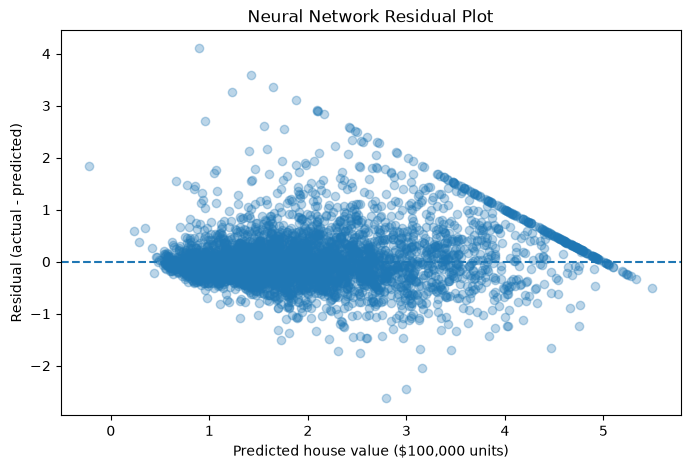

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted house value ($100,000 units)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Neural Network Residual Plot")
plt.show()

### Error by predicted price band

Grouping residuals into bands makes the pattern concrete. Mean absolute error
rises from about **0.20** for predictions up to 1.0 to **0.57** for the 3.0-4.0
band. The mean residual also turns positive for expensive homes (about **+0.18**
in the 3.0-4.0 band and **+0.16** above 4.0), showing that the network
systematically under-predicts the most expensive block groups.

In [41]:
residual_df["predicted_range"] = pd.cut(
    residual_df["predicted"],
    bins=[-float("inf"), 1, 2, 3, 4, float("inf")]
)

summary = residual_df.groupby(
    "predicted_range", observed=True
).agg(
    count=("residual", "size"),
    mean_residual=("residual", "mean"),
    mean_absolute_error=("residual", lambda x: x.abs().mean()),
    residual_std=("residual", "std")
)

print(summary)

                 count  mean_residual  mean_absolute_error  residual_std
predicted_range                                                         
(-inf, 1.0]        489       0.002314             0.202958      0.363229
(1.0, 2.0]        1849      -0.005709             0.288438      0.428159
(2.0, 3.0]        1084       0.054560             0.441514      0.634967
(3.0, 4.0]         482       0.181782             0.572979      0.709081
(4.0, inf]         224       0.163878             0.422987      0.492885


## 7. Compare with a random forest

A random forest is a strong non-linear baseline for tabular data: it needs no
feature scaling, handles interactions automatically and is robust to outliers.
The forest uses 100 trees, `min_samples_leaf=2` and `random_state=42`.

Both models are evaluated on the same validation split and then once on the
held-out test split. Using identical splits and metrics makes the comparison
fair.

In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

final_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_forest.fit(X_train, y_train)

test_predictions = final_forest.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, test_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_predictions)))
print("Test R²:", r2_score(y_test, test_predictions))

Test MAE: 0.3405982476320756
Test RMSE: 0.5162863836284001
Test R²: 0.795798556633577


In [43]:
nn_pred = model.predict(X_val.to_numpy(), verbose=0).ravel()

# Random Forest predictions
rf_pred = final_forest.predict(X_val)

def evaluate_regression(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions)
    }

print("Neural Network:", evaluate_regression(y_val, nn_pred))
print("Random Forest:", evaluate_regression(y_val, rf_pred))

Neural Network: {'MAE': 0.35903441275954706, 'RMSE': np.float64(0.5303437679648232), 'R2': 0.7948659970870093}
Random Forest: {'MAE': 0.3432348353320523, 'RMSE': np.float64(0.5241391548051026), 'R2': 0.7996377393224053}


In [44]:
nn_test_pred = model.predict(X_test.to_numpy(), verbose=0).ravel()
rf_test_pred = final_forest.predict(X_test)

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

print("Neural Network test:", evaluate(y_test, nn_test_pred))
print("Random Forest test:", evaluate(y_test, rf_test_pred))

Neural Network test: {'MAE': 0.3632746638674006, 'RMSE': np.float64(0.5342710048530525), 'R2': 0.7813242242296395}
Random Forest test: {'MAE': 0.3405982476320756, 'RMSE': np.float64(0.5162863836284001), 'R2': 0.795798556633577}


### Results

| Split | Model | MAE | RMSE | R? |
| --- | --- | --- | --- | --- |
| Validation | Neural network | 0.3590 | 0.5303 | 0.7949 |
| Validation | Random forest | 0.3432 | 0.5241 | 0.7996 |
| Test | Neural network | 0.3633 | 0.5343 | 0.7813 |
| Test | Random forest | 0.3406 | 0.5163 | 0.7958 |

The random forest is slightly better on every metric, but the network is close:
the gap is about 0.02 MAE, and both explain roughly 78-80% of the variance in
house value. On this dataset size, the forest's inductive bias is a better match
than a small MLP, which would need more tuning (width, depth, dropout, learning
rate schedule) to close the gap.

## 8. Save and reload the model

Keras models are saved in the native `.keras` format. Saving the full model
includes the architecture, weights and the fitted `Normalization` layer, so the
reloaded model can be called with raw features exactly like the original.

The check predicts the first five test rows with both objects and compares them
with `np.allclose(atol=1e-5)`. Identical predictions confirm that the saved
artifact is complete and reproducible.

In [45]:
model.save("california_housing_nn.keras")

In [46]:
loaded_model = tf.keras.models.load_model(
    "california_housing_nn.keras"
)
original_pred = model.predict(X_test.to_numpy()[:5], verbose=0)
loaded_pred = loaded_model.predict(X_test.to_numpy()[:5], verbose=0)

print("Original predictions:")
print(original_pred.ravel())

print("Reloaded predictions:")
print(loaded_pred.ravel())

print("Predictions match:",
      np.allclose(original_pred, loaded_pred, atol=1e-5))

Original predictions:
[1.4010384  2.5034149  2.1101317  2.0529344  0.93769926]
Reloaded predictions:
[1.4010384  2.5034149  2.1101317  2.0529344  0.93769926]
Predictions match: True


## 9. Summary and next steps

**Final test scores**

| Model | MAE | RMSE | R? |
| --- | --- | --- | --- |
| Neural network | 0.3633 | 0.5343 | 0.7813 |
| Random forest | 0.3406 | 0.5163 | 0.7958 |

**What the notebook demonstrates**

- A complete regression workflow in TensorFlow/Keras: loading, leakage-free
  normalization, model construction, early stopping and test evaluation.
- Why validation loss matters: early stopping prevents the network from
  overfitting past its best epoch.
- How L2 regularization and where normalization lives affect training and
  deployment.
- How to diagnose a regressor with residuals rather than a single aggregate
  metric.
- How to save a full Keras model and verify that it reloads identically.

**Possible next steps**

- Tune capacity and training: wider/deeper layers, dropout, learning-rate
  schedules and larger batch sizes.
- Address the capped target (`MedHouseVal == 5.00001`) with a two-stage
  classifier/regressor.
- Add feature engineering (distance to coast/cities, income ratios) and compare
  with gradient boosting (`HistGradientBoostingRegressor`, XGBoost, LightGBM).
- Use cross-validation instead of a single validation split for more reliable
  model selection.